### 1. Download and Extract Dataset
We will use `kagglehub` to download the Email Spam Classification Dataset (`balaka18/email-spam-classification-dataset-csv`) directly into Colab.

In [1]:
import kagglehub
import pandas as pd
import os

# Download latest version of the dataset
path = kagglehub.dataset_download("balaka18/email-spam-classification-dataset-csv")

print("Path to dataset files:", path)
csv_path = os.path.join(path, "emails.csv")

# Load the dataset
df = pd.read_csv(csv_path)
display(df.head())

Using Colab cache for faster access to the 'email-spam-classification-dataset-csv' dataset.
Path to dataset files: /kaggle/input/email-spam-classification-dataset-csv


,Email No.,the,to,ect,and,for,of,a,you,hou,...,connevey,jay,valued,lay,infrastructure,military,allowing,ff,dry,Prediction
0,Email 1,0,0,1,0,0,0,2,0,0,...,0,0,0,0,0,0,0,0,0,0
1,Email 2,8,13,24,6,6,2,102,1,27,...,0,0,0,0,0,0,0,1,0,0
2,Email 3,0,0,1,0,0,0,8,0,0,...,0,0,0,0,0,0,0,0,0,0
3,Email 4,0,5,22,0,5,1,51,2,10,...,0,0,0,0,0,0,0,0,0,0
4,Email 5,7,6,17,1,5,2,57,0,9,...,0,0,0,0,0,0,0,1,0,0


### 2. Data Preprocessing
We will inspect the dataset, handle any missing values, drop unnecessary columns (like `Email No.`), and split the data into features (`X`) and target labels (`Prediction`). We will also split the dataset into training and testing sets and scale our features.

In [2]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Check basic info
print(df.info())

# Drop unique identifier column 'Email No.'
if 'Email No.' in df.columns:
    X = df.drop(columns=['Email No.', 'Prediction'])
else:
    X = df.drop(columns=['Prediction'])

y = df['Prediction']

# Split into training and testing sets (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Feature Scaling is highly recommended for KNN and SVM
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Training set shape: {X_train_scaled.shape}")
print(f"Testing set shape: {X_test_scaled.shape}")

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5172 entries, 0 to 5171
Columns: 3002 entries, Email No. to Prediction
dtypes: int64(3001), object(1)
memory usage: 118.5+ MB
None
Training set shape: (4137, 3000)
Testing set shape: (1035, 3000)


### 3. Model Training & Evaluation
We will define, train, and evaluate both the **K-Nearest Neighbors (KNN)** and **Support Vector Machine (SVM)** classifiers. We'll measure their performance using Accuracy, Classification Reports, and Confusion Matrices.

In [3]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import seaborn as sns
import matplotlib.pyplot as plt

# --- K-Nearest Neighbors (KNN) ---
print("Training KNN Classifier...")
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_scaled, y_train)
knn_pred = knn.predict(X_test_scaled)

# --- Support Vector Machine (SVM) ---
print("Training SVM Classifier...")
svm = SVC(kernel='rbf', random_state=42)
svm.fit(X_train_scaled, y_train)
svm_pred = svm.predict(X_test_scaled)

Training KNN Classifier...
Training SVM Classifier...


### 4. Performance Analysis and Visualizations

=== K-Nearest Neighbors Performance ===
Accuracy: 0.8338
              precision    recall  f1-score   support

    Not Spam       0.98      0.78      0.87       735
        Spam       0.64      0.96      0.77       300

    accuracy                           0.83      1035
   macro avg       0.81      0.87      0.82      1035
weighted avg       0.88      0.83      0.84      1035


=== Support Vector Machine Performance ===
Accuracy: 0.9304
              precision    recall  f1-score   support

    Not Spam       0.91      0.99      0.95       735
        Spam       0.98      0.77      0.87       300

    accuracy                           0.93      1035
   macro avg       0.95      0.88      0.91      1035
weighted avg       0.93      0.93      0.93      1035



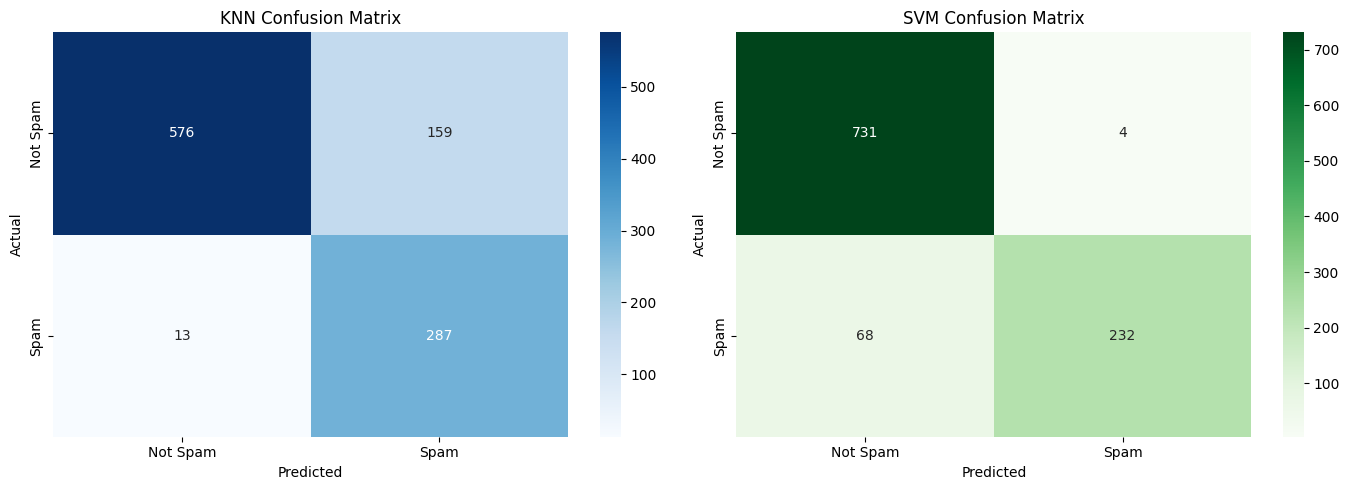

In [4]:
# Print Evaluation Metrics
print("=== K-Nearest Neighbors Performance ===")
print(f"Accuracy: {accuracy_score(y_test, knn_pred):.4f}")
print(classification_report(y_test, knn_pred, target_names=['Not Spam', 'Spam']))

print("\n=== Support Vector Machine Performance ===")
print(f"Accuracy: {accuracy_score(y_test, svm_pred):.4f}")
print(classification_report(y_test, svm_pred, target_names=['Not Spam', 'Spam']))

# Plot Confusion Matrices
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# KNN Confusion Matrix
sns.heatmap(confusion_matrix(y_test, knn_pred), annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=['Not Spam', 'Spam'], yticklabels=['Not Spam', 'Spam'])
axes[0].set_title('KNN Confusion Matrix')
axes[0].set_xlabel('Predicted')
axes[0].set_ylabel('Actual')

# SVM Confusion Matrix
sns.heatmap(confusion_matrix(y_test, svm_pred), annot=True, fmt='d', cmap='Greens', ax=axes[1],
            xticklabels=['Not Spam', 'Spam'], yticklabels=['Not Spam', 'Spam'])
axes[1].set_title('SVM Confusion Matrix')
axes[1].set_xlabel('Predicted')
axes[1].set_ylabel('Actual')

plt.tight_layout()
plt.show()